<a href="https://colab.research.google.com/github/AleAsesino/mineriaDatosAnomaliasABCcarreteras/blob/main/preprocesamientoABCV1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Preprocesamiento**

In [20]:
install.packages(c("dbscan", "mclust"))
library(tidyverse)
library(lubridate)
library(dbscan)
library(mclust)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [21]:
# 1. Cargar dataset crudo
df_raw <- read_csv("data.csv", show_col_types = FALSE)

# Cota superior para eventos aún abiertos (vigentes en la última corrida)
ultima_consulta <- max(ymd_hms(df_raw$fecha_consulta, quiet = TRUE), na.rm = TRUE)

# 2. Limpieza base y filtro de conflicto social (estado LIKE 'e -%')
# - Se excluyen coordenadas (0, 0) inválidas.
# - Se mantienen marcas temporales en hora local de Bolivia (GMT-4) sin convertir a UTC.
df_conflictos <- df_raw %>%
  mutate(
    fecha_consulta = ymd_hms(fecha_consulta, quiet = TRUE),
    fecha_reporte  = ymd_hms(fecha_reporte, quiet = TRUE),
    fecha_fin      = ymd_hms(fecha_fin, quiet = TRUE),
    estado_norm    = str_to_lower(str_squish(coalesce(estado, "")))
  ) %>%
  filter(
    !is.na(fecha_reporte),
    str_starts(estado_norm, "e -"),
    !(latitud == 0 & longitud == 0),
    is.na(fecha_fin) | fecha_fin >= fecha_reporte
  ) %>%
  arrange(latitud, longitud, fecha_reporte)

# 3. Reconstrucción de episodios por coordenada (ventana > 24h separa episodios)
df_episodios <- df_conflictos %>%
  group_by(latitud, longitud) %>%
  mutate(
    fin_efectivo_prev = lag(cummax(as.numeric(coalesce(fecha_fin, ultima_consulta)))),
    fin_efectivo_prev = as_datetime(fin_efectivo_prev, tz = tz(fecha_reporte)),
    nuevo_episodio_flag = if_else(
      is.na(fin_efectivo_prev) |
        as.numeric(difftime(fecha_reporte, fin_efectivo_prev, units = "hours")) > 24,
      1L,
      0L
    ),
    id_episodio_coord = cumsum(nuevo_episodio_flag)
  ) %>%
  ungroup() %>%
  group_by(latitud, longitud, id_episodio_coord) %>%
  summarise(
    inicio_ep     = min(fecha_reporte, na.rm = TRUE),
    es_abierto_ep = any(is.na(fecha_fin)),
    fin_ep_cota   = if_else(any(is.na(fecha_fin)), ultima_consulta, max(fecha_fin, na.rm = TRUE)),
    duracion_ep_h = as.numeric(difftime(fin_ep_cota, inicio_ep, units = "hours")),
    n_filas_ep    = n(),
    .groups = "drop"
  ) %>%
  mutate(dia_inicio = as_date(inicio_ep))

# 4. Episodios iniciados por día
episodios_iniciados_diario <- df_episodios %>%
  group_by(dia = dia_inicio) %>%
  summarise(
    episodios_nuevos      = n(),
    duracion_prom_ep_h    = mean(duracion_ep_h, na.rm = TRUE),
    filas_conflicto_nuevo = sum(n_filas_ep, na.rm = TRUE),
    .groups = "drop"
  )

# 5. Episodios activos cada día (corte a las 12:00 hora local)
rango_dias <- seq.Date(
  from = min(as_date(df_conflictos$fecha_reporte), na.rm = TRUE),
  to   = max(as_date(ultima_consulta), na.rm = TRUE),
  by   = "day"
)

episodios_activos_diario <- tibble(dia = rango_dias) %>%
  rowwise() %>%
  mutate(
    corte_mediodia = as_datetime(paste0(dia, " 12:00:00"), tz = tz(ultima_consulta)),
    episodios_activos = sum(
      df_episodios$inicio_ep <= corte_mediodia & df_episodios$fin_ep_cota >= corte_mediodia,
      na.rm = TRUE
    )
  ) %>%
  ungroup() %>%
  select(dia, episodios_activos)

# Indicador de días con actividad registrada en la fuente
dias_con_actividad <- df_raw %>%
  mutate(dia_rep = as_date(ymd_hms(fecha_reporte, quiet = TRUE))) %>%
  distinct(dia_rep) %>%
  filter(!is.na(dia_rep)) %>%
  mutate(tiene_actividad_fuente = TRUE)

# 6. Consolidar dataset diario limpio
df_diario_limpio <- tibble(dia = rango_dias) %>%
  left_join(episodios_activos_diario, by = "dia") %>%
  left_join(episodios_iniciados_diario, by = "dia") %>%
  left_join(dias_con_actividad, by = c("dia" = "dia_rep")) %>%
  mutate(
    episodios_activos      = replace_na(episodios_activos, 0L),
    episodios_nuevos       = replace_na(episodios_nuevos, 0L),
    filas_conflicto_nuevo  = replace_na(filas_conflicto_nuevo, 0L),
    duracion_prom_ep_h     = replace_na(duracion_prom_ep_h, 0),
    tiene_actividad_fuente = replace_na(tiene_actividad_fuente, FALSE),
    log_episodios_activos  = log1p(episodios_activos),
    log_episodios_nuevos   = log1p(episodios_nuevos),
    log_duracion_prom_h    = log1p(duracion_prom_ep_h)
  )

write_csv(df_diario_limpio, "df_diario_limpio.csv")
cat("Guardado: df_diario_limpio.csv | Filas:", nrow(df_diario_limpio), "\n")
head(df_diario_limpio)

Guardado: df_diario_limpio.csv | Filas: 2292 


dia,episodios_activos,episodios_nuevos,duracion_prom_ep_h,filas_conflicto_nuevo,tiene_actividad_fuente,log_episodios_activos,log_episodios_nuevos,log_duracion_prom_h
<date>,<int>,<int>,<dbl>,<int>,<lgl>,<dbl>,<dbl>,<dbl>
2020-08-13,4,4,64.02389,4,TRUE,1.609438,1.609438,4.174755
2020-08-14,4,0,0.00000,0,TRUE,1.609438,0.000000,0.000000
2020-08-15,11,7,34.99337,7,TRUE,2.484907,2.079442,3.583335
2020-08-16,7,0,0.00000,0,TRUE,2.079442,0.000000,0.000000
2020-08-17,0,0,0.00000,0,TRUE,0.000000,0.000000,0.000000
2020-08-18,0,0,0.00000,0,TRUE,0.000000,0.000000,0.000000


In [22]:
# Cargar CSV limpio (útil si reinicias sesión y vas directo al modelado)
df_model <- read_csv("df_diario_limpio.csv", show_col_types = FALSE)

# Usamos transformaciones logarítmicas estandarizadas para reducir la asimetría de colas largas.
# Si prefieres evaluar días solo con actividad confirmada en la fuente, filtra:
# df_model <- df_model %>% filter(tiene_actividad_fuente)

X_scaled <- df_model %>%
  select(log_episodios_activos, log_duracion_prom_h) %>%
  scale() %>%
  as.matrix()

GMM óptimo -> Componentes (G): 4 | Modelo: EVI 
Anomalías detectadas (GMM P5): 115 


dia,episodios_activos,episodios_nuevos,duracion_prom_ep_h,cluster_gmm,log_dens_gmm
<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2026-06-03,95,1,6.691667,2,-20.42317
2024-10-29,23,1,2.082500,2,-19.79750
2022-11-04,16,1,2.877778,2,-17.65008
2022-10-22,5,11,621.222045,3,-16.82893
2026-05-23,57,1,701.099722,2,-16.50830
2022-11-08,17,1,3.333889,2,-16.36156
2026-05-10,18,1,989.814444,2,-15.86452
2024-08-01,97,86,15.976638,2,-15.50479
2026-06-20,39,1,5.028333,2,-14.41698


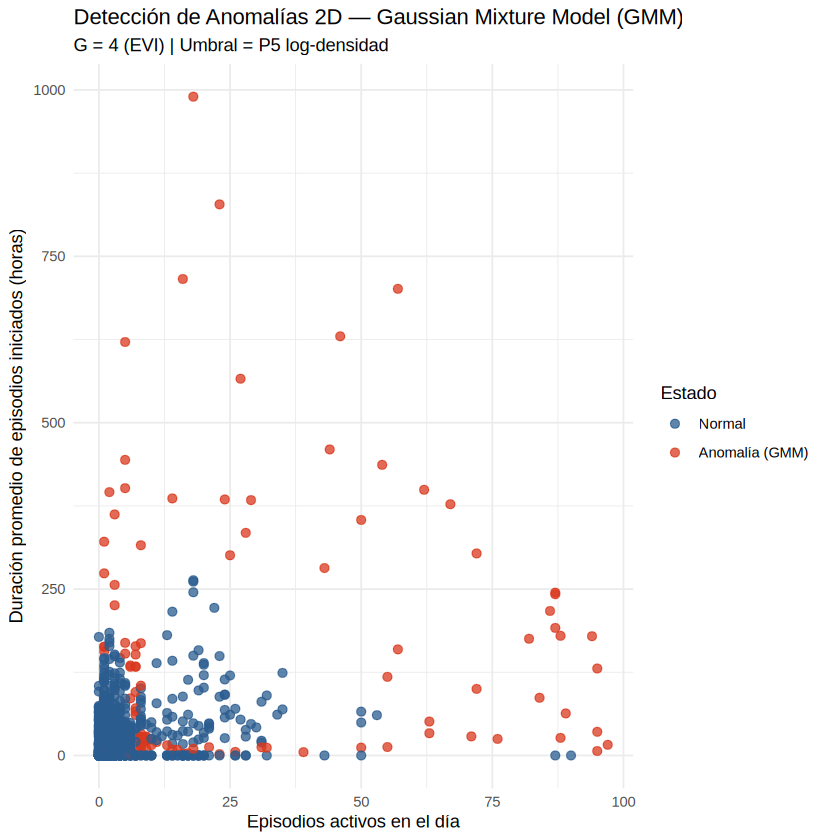

In [23]:
# 1. Ajustar GMM seleccionando número de componentes (1 a 6) y covarianza por BIC
gmm_fit <- Mclust(X_scaled, G = 1:6, verbose = FALSE)

# 2. Log-densidad bajo la mezcla Gaussiana:
# Usamos dens() pasando modelName y parameters de gmm_fit (o gmm_fit$density)
densidad_gmm <- dens(
  modelName  = gmm_fit$modelName,
  data       = X_scaled,
  parameters = gmm_fit$parameters,
  logarithm  = FALSE
)
log_dens_gmm <- log(pmax(densidad_gmm, .Machine$double.xmin))

# Umbral: 5% con menor densidad (percentil 5 de log-densidad)
umbral_gmm <- quantile(log_dens_gmm, probs = 0.05, na.rm = TRUE)

df_model <- df_model %>%
  mutate(
    cluster_gmm  = gmm_fit$classification,
    log_dens_gmm = log_dens_gmm,
    anomalia_gmm = log_dens_gmm < umbral_gmm
  )

cat("GMM óptimo -> Componentes (G):", gmm_fit$G, "| Modelo:", gmm_fit$modelName, "\n")
cat("Anomalías detectadas (GMM P5):", sum(df_model$anomalia_gmm), "\n")

df_model %>%
  filter(anomalia_gmm) %>%
  arrange(log_dens_gmm) %>%
  select(dia, episodios_activos, episodios_nuevos, duracion_prom_ep_h, cluster_gmm, log_dens_gmm) %>%
  head(10)

# Gráfico 2D - GMM
ggplot(df_model, aes(x = episodios_activos, y = duracion_prom_ep_h, color = anomalia_gmm)) +
  geom_point(alpha = 0.75, size = 2.2) +
  scale_color_manual(
    values = c("FALSE" = "#2b5c8f", "TRUE" = "#d9381e"),
    labels = c("Normal", "Anomalía (GMM)")
  ) +
  labs(
    title = "Detección de Anomalías 2D — Gaussian Mixture Model (GMM)",
    subtitle = paste0("G = ", gmm_fit$G, " (", gmm_fit$modelName, ") | Umbral = P5 log-densidad"),
    x = "Episodios activos en el día",
    y = "Duración promedio de episodios iniciados (horas)",
    color = "Estado"
  ) +
  theme_minimal()

Anomalías detectadas (LOF P95): 115 


dia,episodios_activos,episodios_nuevos,duracion_prom_ep_h,score_lof
<date>,<dbl>,<dbl>,<dbl>,<dbl>
2024-05-14,0,1,0.09666667,Inf
2026-06-17,50,0,0.00000000,4.441155
2026-06-11,90,0,0.00000000,4.355652
2026-06-12,87,0,0.00000000,4.278296
2026-06-19,43,0,0.00000000,3.885301
2024-10-29,23,1,2.08250000,3.689023
2025-12-04,0,1,178.14583333,3.593496
2022-11-04,16,1,2.87777778,3.475036
2022-11-08,17,1,3.33388889,3.183985


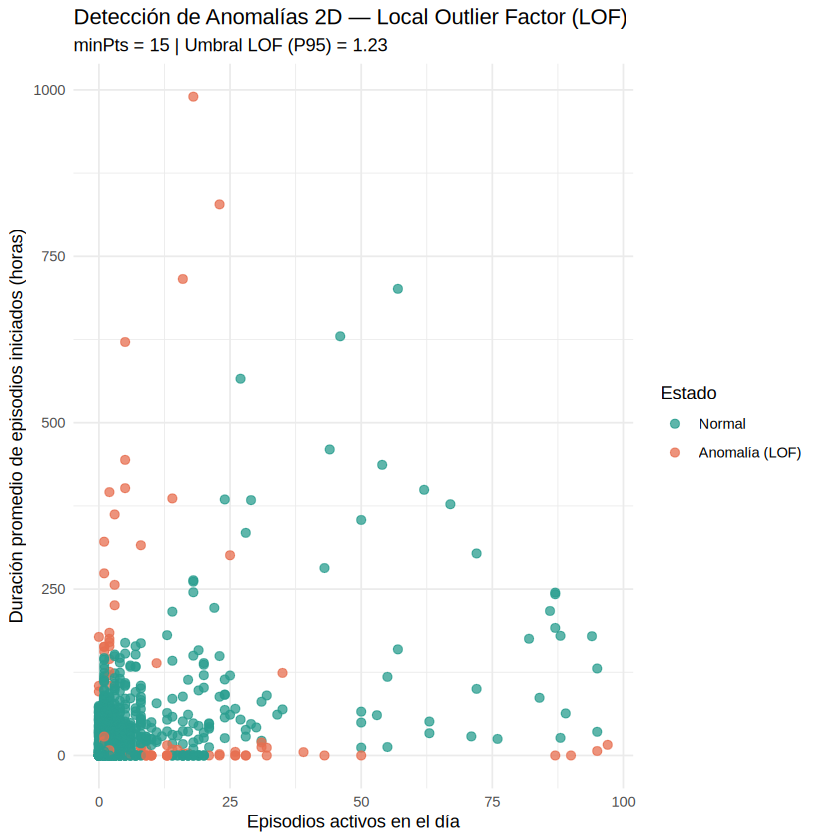

In [24]:
# 1. Calcular puntaje LOF (valores > 1 indican menor densidad local respecto a vecinos)
min_pts <- 15
scores_lof <- lof(X_scaled, minPts = min_pts)

# Umbral: percentil 95 de LOF
umbral_lof <- quantile(scores_lof, probs = 0.95, na.rm = TRUE)

df_model <- df_model %>%
  mutate(
    score_lof    = scores_lof,
    anomalia_lof = score_lof > umbral_lof
  )

cat("Anomalías detectadas (LOF P95):", sum(df_model$anomalia_lof), "\n")

df_model %>%
  filter(anomalia_lof) %>%
  arrange(desc(score_lof)) %>%
  select(dia, episodios_activos, episodios_nuevos, duracion_prom_ep_h, score_lof) %>%
  head(10)

# Gráfico 2D - LOF
ggplot(df_model, aes(x = episodios_activos, y = duracion_prom_ep_h, color = anomalia_lof)) +
  geom_point(alpha = 0.75, size = 2.2) +
  scale_color_manual(
    values = c("FALSE" = "#2a9d8f", "TRUE" = "#e76f51"),
    labels = c("Normal", "Anomalía (LOF)")
  ) +
  labs(
    title = "Detección de Anomalías 2D — Local Outlier Factor (LOF)",
    subtitle = paste0("minPts = ", min_pts, " | Umbral LOF (P95) = ", round(umbral_lof, 2)),
    x = "Episodios activos en el día",
    y = "Duración promedio de episodios iniciados (horas)",
    color = "Estado"
  ) +
  theme_minimal()

In [25]:
# Tabla cruzada de acuerdos y discrepancias
table(GMM = df_model$anomalia_gmm, LOF = df_model$anomalia_lof)

# Días marcados como anomalía por ambos métodos
df_model %>%
  filter(anomalia_gmm & anomalia_lof) %>%
  arrange(desc(episodios_activos)) %>%
  select(dia, episodios_activos, episodios_nuevos, duracion_prom_ep_h, log_dens_gmm, score_lof) %>%
  head(15)

       LOF
GMM     FALSE TRUE
  FALSE  2102   75
  TRUE     75   40

dia,episodios_activos,episodios_nuevos,duracion_prom_ep_h,log_dens_gmm,score_lof
<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2024-08-01,97,86,15.976638,-15.504787,1.243798
2026-06-03,95,1,6.691667,-20.423166,1.326064
2026-06-20,39,1,5.028333,-14.416976,1.313950
2025-06-10,32,10,11.675333,-7.974269,1.292460
2026-01-12,31,7,12.398730,-7.536501,1.266594
2024-02-02,26,2,5.410139,-12.547508,1.249973
2026-05-06,25,12,300.798611,-6.511302,1.237902
2024-10-29,23,1,2.082500,-19.797500,3.689023
2026-05-16,23,1,827.989167,-13.998700,1.293493


analisis Por fechas 2025 y 2026

In [29]:
# 1. Agrupar anomalías por Año y Mes para ver la distribución temporal
anomalias_temporal <- df_model %>%
  mutate(anio_mes = floor_date(dia, "month")) %>%
  group_by(anio_mes) %>%
  summarise(
    total_dias = n(),
    gmm_anomalias = sum(anomalia_gmm),
    lof_anomalias = sum(anomalia_lof),
    coincidentes = sum(anomalia_gmm & anomalia_lof),
    .groups = "drop"
  ) %>%
  arrange(desc(coincidentes))

cat("--- Meses con mayor concentración de anomalías coincidentes ---\n")
print(head(anomalias_temporal, 10))

--- Meses con mayor concentración de anomalías coincidentes ---
# A tibble: 10 × 5
   anio_mes   total_dias gmm_anomalias lof_anomalias coincidentes
   <date>          <int>         <int>         <int>        <int>
 1 2024-10-01         31             5             6            4
 2 2026-05-01         31            22             6            4
 3 2022-07-01         31             3             4            3
 4 2022-11-01         30             3             3            3
 5 2024-02-01         29             3             4            3
 6 2022-10-01         31             6             3            2
 7 2024-06-01         30             2             2            2
 8 2024-08-01         31             3             4            2
 9 2026-06-01         30            14             7            2
10 2020-11-01         30             1             3            1


In [30]:

# 2. Listar los top 15 días individuales más críticos (coincidentes) ordenados por nivel de actividad
dias_criticos <- df_model %>%
  filter(anomalia_gmm & anomalia_lof) %>%
  arrange(desc(episodios_activos), desc(episodios_nuevos)) %>%
  select(dia, episodios_activos, episodios_nuevos, duracion_prom_ep_h, score_lof, log_dens_gmm)

cat("\n--- Top 15 días individuales con mayor conflictividad anómala (Coincidencia GMM y LOF) ---\n")
print(head(dias_criticos, 15))


--- Top 15 días individuales con mayor conflictividad anómala (Coincidencia GMM y LOF) ---
# A tibble: 15 × 6
   dia        episodios_activos episodios_nuevos duracion_prom_ep_h score_lof
   <date>                 <dbl>            <dbl>              <dbl>     <dbl>
 1 2024-08-01                97               86              16.0       1.24
 2 2026-06-03                95                1               6.69      1.33
 3 2026-06-20                39                1               5.03      1.31
 4 2025-06-10                32               10              11.7       1.29
 5 2026-01-12                31                7              12.4       1.27
 6 2024-02-02                26                2               5.41      1.25
 7 2026-05-06                25               12             301.        1.24
 8 2024-10-29                23                1               2.08      3.69
 9 2026-05-16                23                1             828.        1.29
10 2026-05-10                18

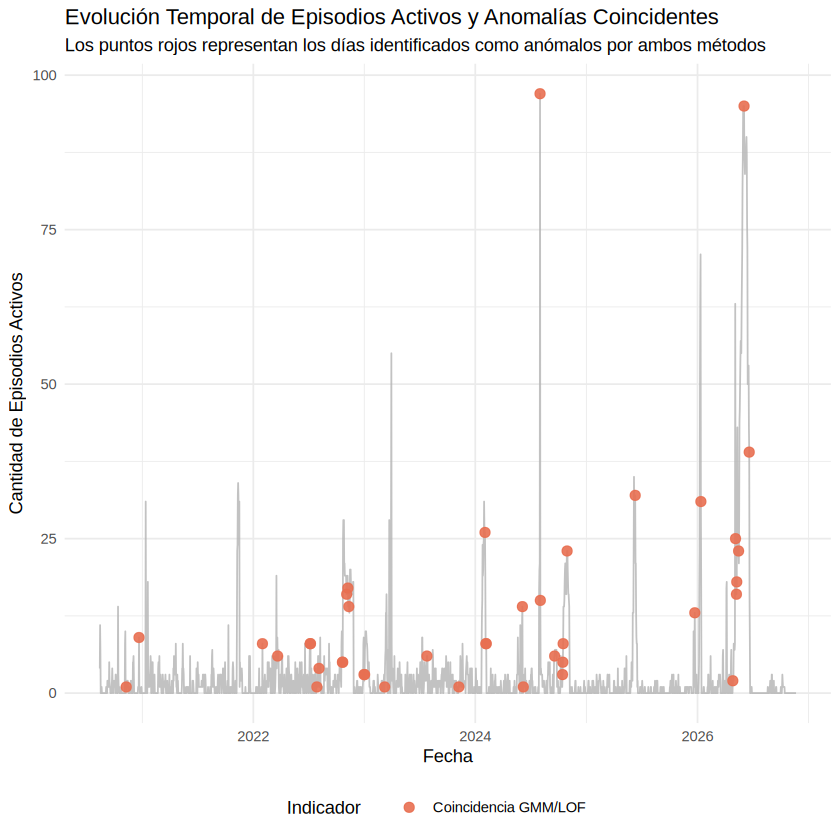

In [31]:

# 3. Gráfico temporal destacando las anomalías coincidentes en la serie de tiempo
ggplot(df_model, aes(x = dia, y = episodios_activos)) +
  geom_line(color = "gray70", alpha = 0.8) +
  geom_point(data = filter(df_model, anomalia_gmm & anomalia_lof),
             aes(color = "Coincidencia GMM/LOF"), size = 2.5, alpha = 0.9) +
  scale_color_manual(values = c("Coincidencia GMM/LOF" = "#e76f51")) +
  labs(
    title = "Evolución Temporal de Episodios Activos y Anomalías Coincidentes",
    subtitle = "Los puntos rojos representan los días identificados como anómalos por ambos métodos",
    x = "Fecha",
    y = "Cantidad de Episodios Activos",
    color = "Indicador"
  ) +
  theme_minimal() +
  theme(legend.position = "bottom")

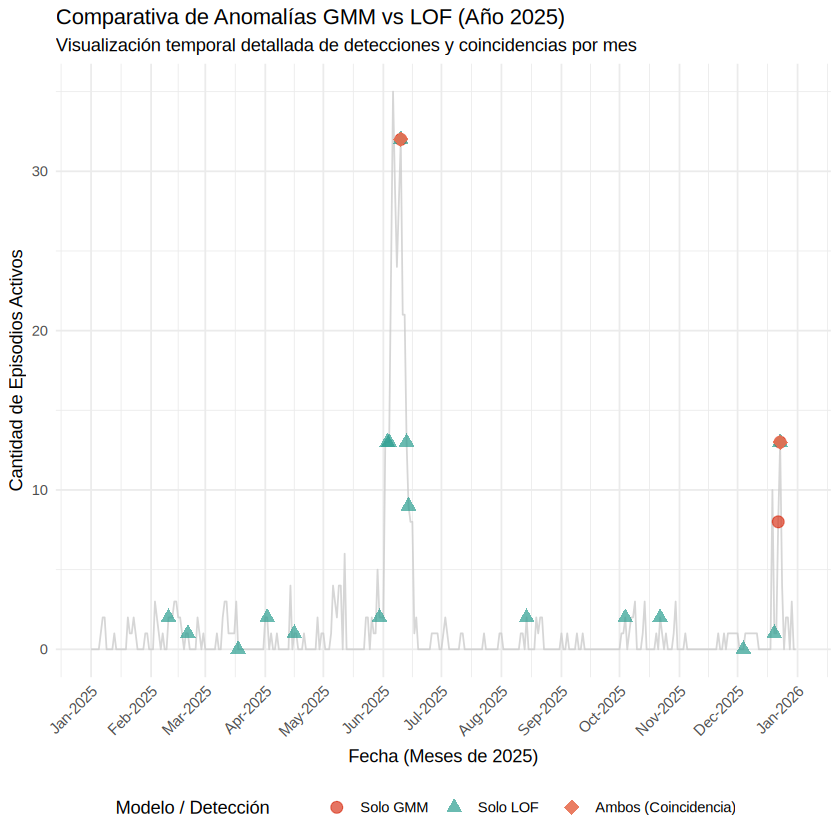

In [32]:

# Filtrar el conjunto de datos únicamente para el año 2025
df_2025 <- df_model %>%
  filter(year(dia) == 2025)

# Crear un gráfico comparativo de ambos modelos solo para el 2025
ggplot(df_2025, aes(x = dia, y = episodios_activos)) +
  geom_line(color = "gray80", alpha = 0.8) +
  # Puntos para anomalías GMM
  geom_point(data = filter(df_2025, anomalia_gmm),
             aes(color = "Solo GMM"), size = 3, alpha = 0.7) +
  # Puntos para anomalías LOF
  geom_point(data = filter(df_2025, anomalia_lof),
             aes(color = "Solo LOF"), size = 3, alpha = 0.7, shape = 17) +
  # Resaltar la coincidencia de ambos
  geom_point(data = filter(df_2025, anomalia_gmm & anomalia_lof),
             aes(color = "Ambos (Coincidencia)"), size = 4, alpha = 0.9, shape = 18) +
  scale_color_manual(
    values = c("Solo GMM" = "#d9381e", "Solo LOF" = "#2a9d8f", "Ambos (Coincidencia)" = "#e76f51"),
    breaks = c("Solo GMM", "Solo LOF", "Ambos (Coincidencia)")
  ) +
  scale_x_date(date_breaks = "1 month", date_labels = "%b-%Y") +
  labs(
    title = "Comparativa de Anomalías GMM vs LOF (Año 2025)",
    subtitle = "Visualización temporal detallada de detecciones y coincidencias por mes",
    x = "Fecha (Meses de 2025)",
    y = "Cantidad de Episodios Activos",
    color = "Modelo / Detección"
  ) +
  theme_minimal() +
  theme(
    legend.position = "bottom",
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

In [33]:

# Resumen en texto de las anomalías detectadas en 2025
resumen_2025 <- df_2025 %>%
  summarise(
    Total_Dias = n(),
    Anomalias_GMM = sum(anomalia_gmm),
    Anomalias_LOF = sum(anomalia_lof),
    Coincidentes = sum(anomalia_gmm & anomalia_lof)
  )

cat("--- Resumen de anomalías detectadas durante el año 2025 ---\n")
print(resumen_2025)

--- Resumen de anomalías detectadas durante el año 2025 ---
# A tibble: 1 × 4
  Total_Dias Anomalias_GMM Anomalias_LOF Coincidentes
       <int>         <int>         <int>        <int>
1        365             3            17            2


Graficos del 2026

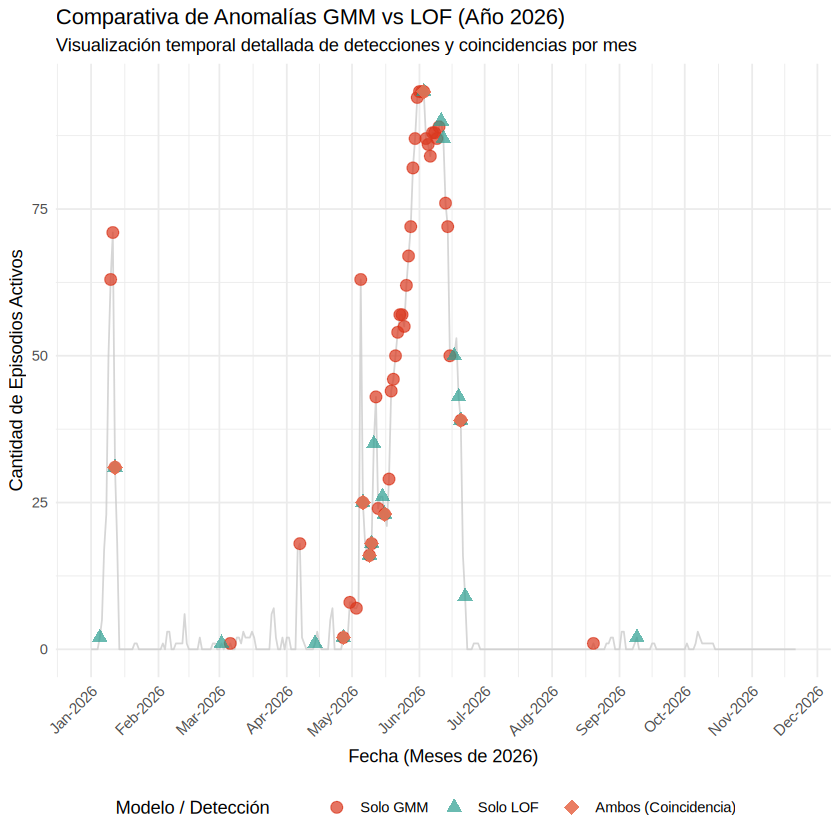

In [34]:

# Filtrar el conjunto de datos únicamente para el año 2026
df_2026 <- df_model %>%
  filter(year(dia) == 2026)

# Crear un gráfico comparativo de ambos modelos solo para el 2026
ggplot(df_2026, aes(x = dia, y = episodios_activos)) +
  geom_line(color = "gray80", alpha = 0.8) +
  # Puntos para anomalías GMM
  geom_point(data = filter(df_2026, anomalia_gmm),
             aes(color = "Solo GMM"), size = 3, alpha = 0.7) +
  # Puntos para anomalías LOF
  geom_point(data = filter(df_2026, anomalia_lof),
             aes(color = "Solo LOF"), size = 3, alpha = 0.7, shape = 17) +
  # Resaltar la coincidencia de ambos
  geom_point(data = filter(df_2026, anomalia_gmm & anomalia_lof),
             aes(color = "Ambos (Coincidencia)"), size = 4, alpha = 0.9, shape = 18) +
  scale_color_manual(
    values = c("Solo GMM" = "#d9381e", "Solo LOF" = "#2a9d8f", "Ambos (Coincidencia)" = "#e76f51"),
    breaks = c("Solo GMM", "Solo LOF", "Ambos (Coincidencia)")
  ) +
  scale_x_date(date_breaks = "1 month", date_labels = "%b-%Y") +
  labs(
    title = "Comparativa de Anomalías GMM vs LOF (Año 2026)",
    subtitle = "Visualización temporal detallada de detecciones y coincidencias por mes",
    x = "Fecha (Meses de 2026)",
    y = "Cantidad de Episodios Activos",
    color = "Modelo / Detección"
  ) +
  theme_minimal() +
  theme(
    legend.position = "bottom",
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

In [35]:

# Resumen en texto de las anomalías detectadas en 2026
resumen_2026 <- df_2026 %>%
  summarise(
    Total_Dias = n(),
    Anomalias_GMM = sum(anomalia_gmm),
    Anomalias_LOF = sum(anomalia_lof),
    Coincidentes = sum(anomalia_gmm & anomalia_lof)
  )

cat("--- Resumen de anomalías detectadas durante el año 2026 ---\n")
print(resumen_2026)

--- Resumen de anomalías detectadas durante el año 2026 ---
# A tibble: 1 × 4
  Total_Dias Anomalias_GMM Anomalias_LOF Coincidentes
       <int>         <int>         <int>        <int>
1        325            44            19            8


# **Horas de reporte.**

In [38]:

# 1. Cargar datos originales y extraer la hora de reporte de los conflictos
df_horas <- df_raw %>%
  mutate(
    fecha_reporte = ymd_hms(fecha_reporte, quiet = TRUE),
    dia = as_date(fecha_reporte),
    hora = hour(fecha_reporte)
  ) %>%
  filter(!is.na(hora)) %>%
  # Unir con el dataset de modelos para saber si el día fue anómalo
  left_join(
    select(df_model, dia, anomalia_gmm, anomalia_lof),
    by = "dia"
  ) %>%
  mutate(
    tipo_dia = case_when(
      anomalia_gmm & anomalia_lof ~ "Ambos (Coincidencia)",
      anomalia_gmm ~ "Anomalía GMM",
      anomalia_lof ~ "Anomalía LOF",
      TRUE ~ "Día Normal"
    )
  )

# 2. Resumir cantidad de reportes por hora y tipo de día
reportes_por_hora <- df_horas %>%
  group_by(hora, tipo_dia) %>%
  summarise(cantidad = n(), .groups = "drop")

head(reportes_por_hora)

hora,tipo_dia,cantidad
<int>,<chr>,<int>
0,Ambos (Coincidencia),20
0,Anomalía GMM,23
0,Anomalía LOF,6
0,Día Normal,161
1,Anomalía GMM,4
1,Anomalía LOF,3


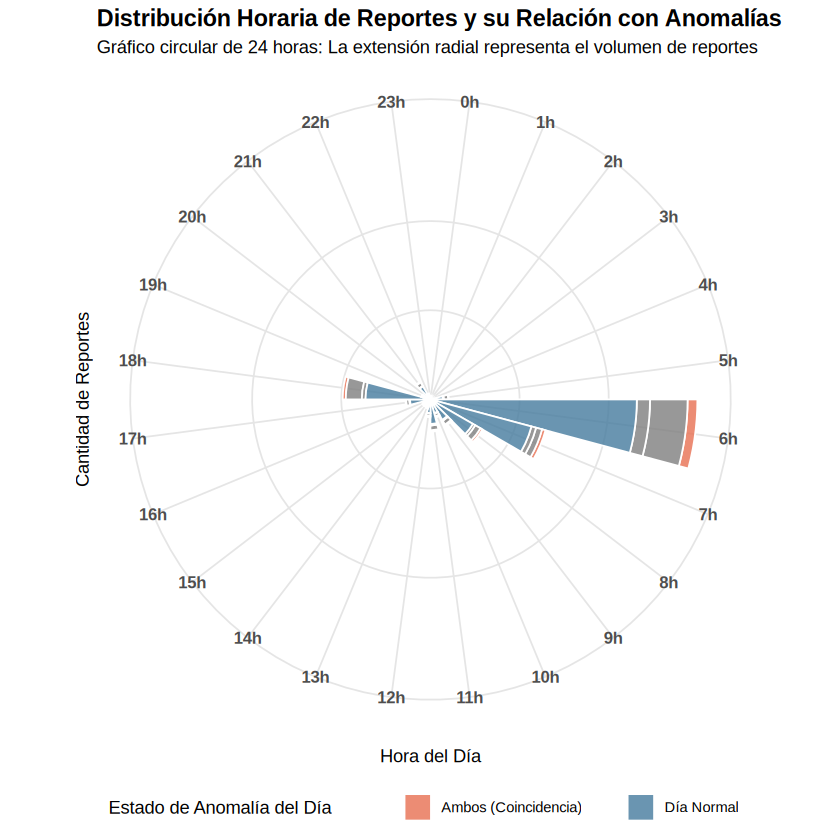

In [39]:

# 3. Gráfico circular (Coxcomb / Rosa de Vientos de 24 Horas) que se extiende según la cantidad de reportes
ggplot(reportes_por_hora, aes(x = factor(hora), y = cantidad, fill = tipo_dia)) +
  geom_bar(stat = "identity", width = 1, color = "white", alpha = 0.8) +
  # Transformar a coordenadas polares para crear el efecto circular (reloj)
  coord_polar(start = 0) +
  scale_x_discrete(
    breaks = 0:23,
    labels = paste0(0:23, "h")
  ) +
  scale_fill_manual(
    values = c(
      "Día Normal" = "#457b9d",
      "Solo GMM" = "#d9381e",
      "Solo LOF" = "#2a9d8f",
      "Ambos (Coincidencia)" = "#e76f51"
    )
  ) +
  labs(
    title = "Distribución Horaria de Reportes y su Relación con Anomalías",
    subtitle = "Gráfico circular de 24 horas: La extensión radial representa el volumen de reportes",
    x = "Hora del Día",
    y = "Cantidad de Reportes",
    fill = "Estado de Anomalía del Día"
  ) +
  theme_minimal() +
  theme(
    axis.text.y = element_blank(),
    axis.ticks.y = element_blank(),
    panel.grid.major = element_line(color = "gray90"),
    legend.position = "bottom",
    plot.title = element_text(face = "bold", size = 14),
    axis.text.x = element_text(size = 10, face = "bold")
  )

```markdown
# **Análisis Geoespacial: Mapa de Puntos de Anomalías**
```

In [ ]:
#@title
# Nota: El código se ejecuta en entorno R para mantener consistencia con los datos procesados en memoria.

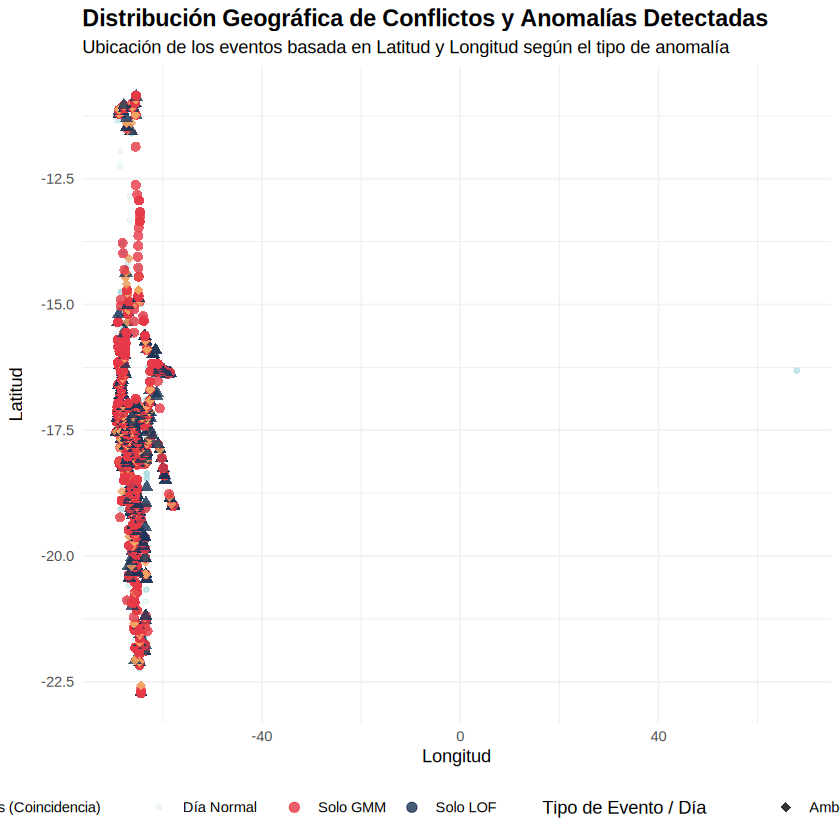

In [40]:
# 1. Unir las coordenadas de los conflictos con las clasificaciones de anomalías diarias
df_mapa <- df_conflictos %>%
  mutate(dia = as_date(fecha_reporte)) %>%
  left_join(
    select(df_model, dia, anomalia_gmm, anomalia_lof),
    by = "dia"
  ) %>%
  mutate(
    tipo_anomalia = case_when(
      anomalia_gmm & anomalia_lof ~ "Ambos (Coincidencia)",
      anomalia_gmm ~ "Solo GMM",
      anomalia_lof ~ "Solo LOF",
      TRUE ~ "Día Normal"
    )
  )

# 2. Generar el mapa de dispersión por latitud y longitud
ggplot(df_mapa, aes(x = longitud, y = latitud)) +
  # Dibujar los puntos de días normales en el fondo
  geom_point(data = filter(df_mapa, tipo_anomalia == "Día Normal"),
             aes(color = "Día Normal"), alpha = 0.2, size = 1.2) +
  # Resaltar las anomalías detectadas por los modelos arriba
  geom_point(data = filter(df_mapa, tipo_anomalia != "Día Normal"),
             aes(color = tipo_anomalia, shape = tipo_anomalia), alpha = 0.8, size = 2.5) +
  scale_color_manual(
    values = c(
      "Día Normal" = "#a8dadc",
      "Solo GMM" = "#e63946",
      "Solo LOF" = "#1d3557",
      "Ambos (Coincidencia)" = "#f4a261"
    )
  ) +
  scale_shape_manual(
    values = c(
      "Solo GMM" = 16,
      "Solo LOF" = 17,
      "Ambos (Coincidencia)" = 18
    )
  ) +
  labs(
    title = "Distribución Geográfica de Conflictos y Anomalías Detectadas",
    subtitle = "Ubicación de los eventos basada en Latitud y Longitud según el tipo de anomalía",
    x = "Longitud",
    y = "Latitud",
    color = "Tipo de Evento / Día",
    shape = "Tipo de Evento / Día"
  ) +
  theme_minimal() +
  theme(
    legend.position = "bottom",
    plot.title = element_text(face = "bold", size = 14),
    panel.grid.major = element_line(color = "gray95")
  )

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)


Attaching package: ‘maps’


The following object is masked from ‘package:mclust’:

    map


The following object is masked from ‘package:purrr’:

    map


Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


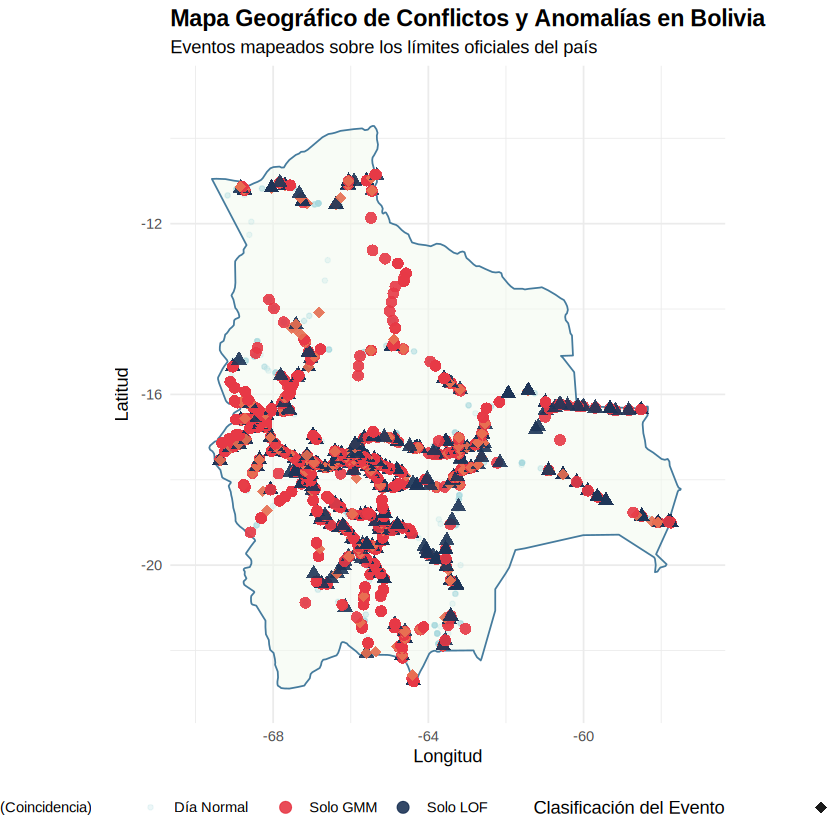

In [42]:

# Instalar el paquete 'maps' requerido por map_data() si no está presente
if (!requireNamespace("maps", quietly = TRUE)) {
  install.packages("maps")
}
library(maps)

# Cargar los límites de los mapas
bolivia_map <- map_data("world", region = "Bolivia")

# Generar el mapa geográfico real de Bolivia con los puntos encima
ggplot() +
  # 1. Dibujar el mapa base de Bolivia (polígonos de las fronteras)
  geom_polygon(data = bolivia_map, aes(x = long, y = lat, group = group),
               fill = "#f1faee", color = "#457b9d", size = 0.5, alpha = 0.5) +
  # 2. Dibujar los puntos de días normales en el fondo
  geom_point(data = filter(df_mapa, tipo_anomalia == "Día Normal"),
             aes(x = longitud, y = latitud, color = "Día Normal"),
             alpha = 0.2, size = 1.2) +
  # 3. Resaltar las anomalías arriba del mapa base
  geom_point(data = filter(df_mapa, tipo_anomalia != "Día Normal"),
             aes(x = longitud, y = latitud, color = tipo_anomalia, shape = tipo_anomalia),
             alpha = 0.9, size = 3) +
  scale_color_manual(
    values = c(
      "Día Normal" = "#a8dadc",
      "Solo GMM" = "#e63946",
      "Solo LOF" = "#1d3557",
      "Ambos (Coincidencia)" = "#e76f51"
    )
  ) +
  scale_shape_manual(
    values = c(
      "Solo GMM" = 16,
      "Solo LOF" = 17,
      "Ambos (Coincidencia)" = 18
    )
  ) +
  # Ajustar límites visuales aproximados de Bolivia para encuadrar bien
  coord_fixed(xlim = c(-70, -57), ylim = c(-23, -9), ratio = 1.1) +
  labs(
    title = "Mapa Geográfico de Conflictos y Anomalías en Bolivia",
    subtitle = "Eventos mapeados sobre los límites oficiales del país",
    x = "Longitud",
    y = "Latitud",
    color = "Clasificación del Evento",
    shape = "Clasificación del Evento"
  ) +
  theme_minimal() +
  theme(
    legend.position = "bottom",
    plot.title = element_text(face = "bold", size = 14),
    panel.grid.major = element_line(color = "gray92")
  )